In [ ]:
from alpaca.data.historical import StockHistoricalDataClient
from alpaca.data.requests import StockBarsRequest
from alpaca.data.timeframe import TimeFrame
import pandas as pd
from datetime import datetime
from pathlib import Path
from env import API_KEY, SECRET_KEY

# Usar caché local para evitar límites de la API de Alpaca
csv_path = Path("aapl_raw.csv")

if csv_path.exists():
    df = pd.read_csv(csv_path, parse_dates=["timestamp"])
    print(f"Datos cargados desde CSV local: {csv_path} ({len(df)} registros)")
else:
    client = StockHistoricalDataClient(API_KEY, SECRET_KEY)

    request_params = StockBarsRequest(
        symbol_or_symbols="AAPL",
        timeframe=TimeFrame.Day,
        start=datetime(2020, 1, 1),
        end=datetime(2024, 1, 1)
    )

    bars = client.get_stock_bars(request_params)
    df = bars.df.reset_index()
    df.to_csv(csv_path, index=False)
    print(f"Datos descargados y guardados en: {csv_path} ({len(df)} registros)")

assert len(df) > 800, f"Total de registro obtenidos: {len(df)}"
df.head()

Datos descargados y guardados en: aapl_raw.csv (1006 registros)


,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,AAPL,2020-01-02 05:00:00+00:00,296.24,300.6000,295.190,300.35,36554338.0,283489.0,298.546196
1,AAPL,2020-01-03 05:00:00+00:00,297.15,300.5800,296.500,297.43,38677814.0,280441.0,298.834372
2,AAPL,2020-01-06 05:00:00+00:00,293.79,299.9600,292.750,299.80,31399992.0,242868.0,297.813476
3,AAPL,2020-01-07 05:00:00+00:00,299.84,300.9000,297.480,298.39,29556784.0,227871.0,299.034972
4,AAPL,2020-01-08 05:00:00+00:00,297.16,304.4399,297.156,303.19,35684201.0,261773.0,301.304133


In [ ]:
from sklearn.preprocessing import StandardScaler

# Seleccionar columnas relevantes
features = ['open', 'high', 'low', 'volume', 'vwap', 'trade_count']

# Feature Engineering: Promedios móviles de 5 y 10 días
df['SMA_5'] = df['close'].rolling(window=5).mean()
df['SMA_10'] = df['close'].rolling(window=10).mean()

features.extend(['SMA_5', 'SMA_10'])

# Variable objetivo (Precio de cierre del día siguiente)
df['Target'] = df['close'].shift(-1)

df = df.dropna()

X = df[features]
y = df['Target']

# Normalización (Estandarización)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print(f"Registros después de la limpieza: {len(X_scaled_df)}")
X_scaled_df.head()

Registros después de la limpieza: 996


,open,high,low,volume,vwap,trade_count,SMA_5,SMA_10
0,1.775988,1.768720,1.793867,-1.279799,1.783612,-1.410520,1.782228,1.709802
1,1.799574,1.771392,1.828712,-1.353665,1.800097,-1.623212,1.797507,1.730264
2,1.835902,1.812003,1.868633,-1.121557,1.838283,-1.509131,1.820384,1.759534
3,1.848373,1.815744,1.882351,-1.298204,1.842658,-1.617628,1.819322,1.782579
4,1.867215,1.828702,1.900322,-1.391137,1.858202,-1.619948,1.832994,1.809114


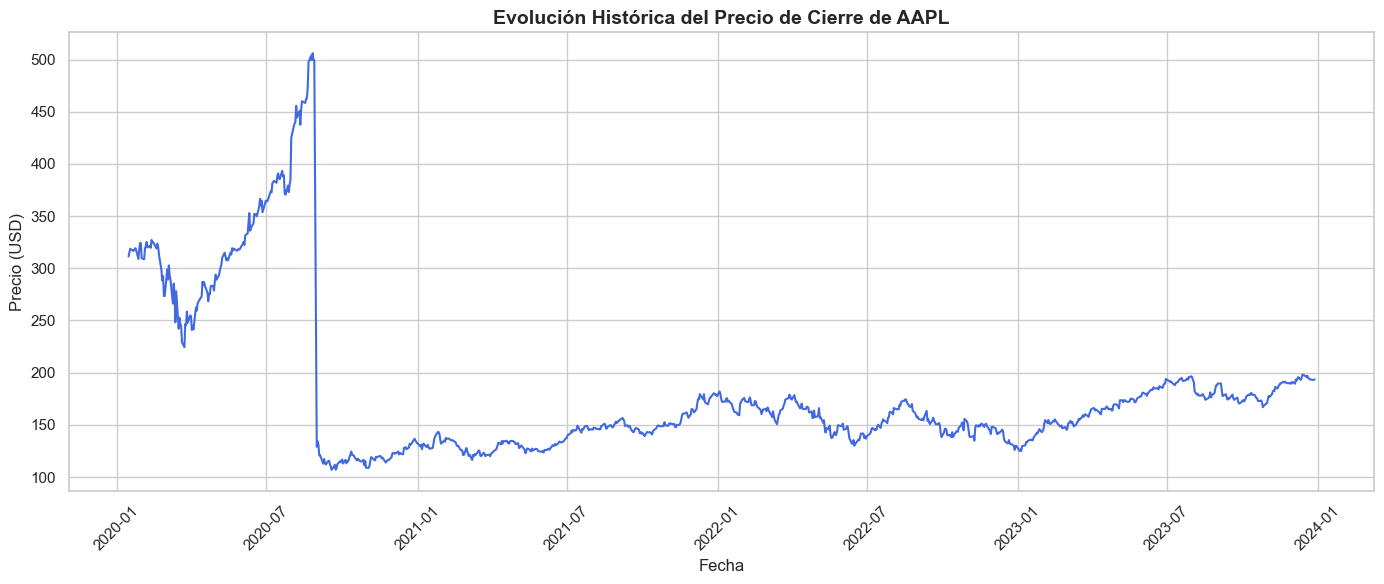

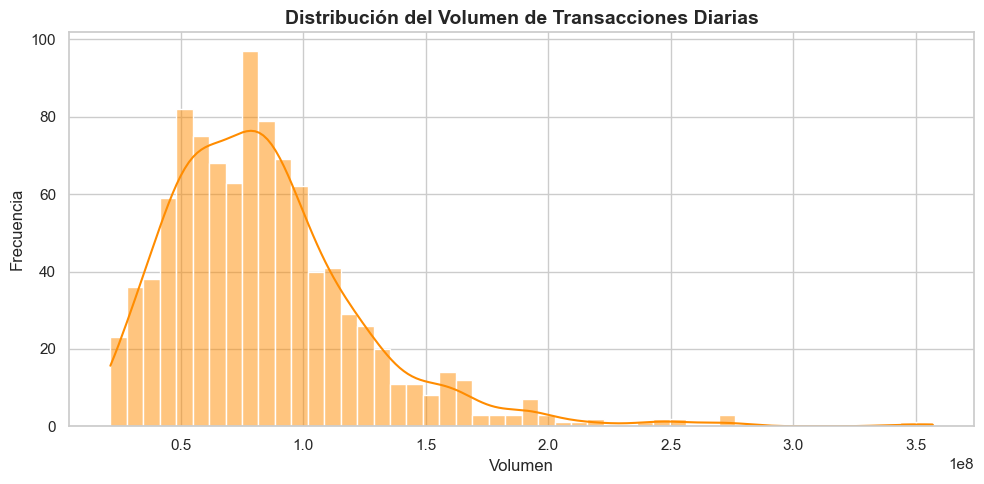

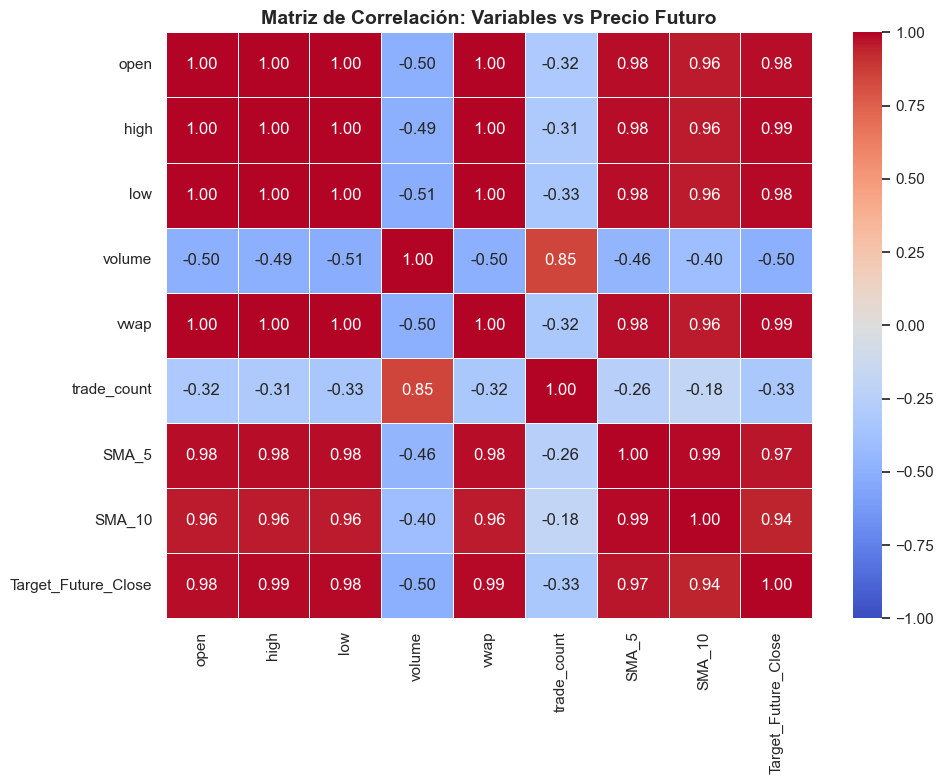

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual de las gráficas
sns.set_theme(style="whitegrid")

# 1. Evolución Histórica del Precio (Análisis Bivariado)
plt.figure(figsize=(14, 6))
plt.plot(df['timestamp'], df['close'], color='royalblue', linewidth=1.5)
plt.title('Evolución Histórica del Precio de Cierre de AAPL', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precio (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Distribución del Volumen de Transacciones (Análisis Univariado)
plt.figure(figsize=(10, 5))
sns.histplot(df['volume'], bins=50, kde=True, color='darkorange')
plt.title('Distribución del Volumen de Transacciones Diarias', fontsize=14, fontweight='bold')
plt.xlabel('Volumen', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Mapa de Calor de Correlación (Análisis Multivariado)
eda_df = X_scaled_df.copy()
eda_df['Target_Future_Close'] = y.values

plt.figure(figsize=(10, 8))

correlation_matrix = eda_df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlación: Variables vs Precio Futuro', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()